In [2]:
import sys
import os
import os.path as op

PROJECT_DIR = '/data/NSSP'
os.chdir(PROJECT_DIR)
notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist

import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.list()

loadFSL()

import fsl.wrappers
from fsl.wrappers import fslmaths, mcflirt, fast, bet, flirt
from fsl.wrappers.misc import fslroi

import glob
import subprocess
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn import plotting, image


In [3]:
%gui wx


(ipykernel_launcher.py:1093): dbind-WARNING **: 21:26:59.440: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/1601445503/at-spi/bus_100: No such file or directory


In [4]:
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

21:27:19: Debug: Adding duplicate image handler for 'Windows bitmap file'
21:27:19: Debug: Adding duplicate animation handler for '1' type
21:27:19: Debug: Adding duplicate animation handler for '2' type
21:27:19: Debug: Adding duplicate image handler for 'Windows bitmap file'
21:27:19: Debug: Adding duplicate animation handler for '1' type
21:27:19: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:1093): Gtk-CRITICAL **: 21:27:19.827: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:1093): Gtk-CRITICAL **: 21:27:21.974: gtk_window_resize: assertion 'width > 0' failed


In [5]:
PROJECT_DIR = '/data/NSSP'
os.chdir(PROJECT_DIR)
DATA_ROOT = op.join(PROJECT_DIR, 'Data')
T1_PATH = op.join(DATA_ROOT, 'T1', 'T1w.nii.gz')

PREPROCESS_DATA_ROOT = op.join(PROJECT_DIR, 'derivatives', 'preprocessed_data')
mkdir_no_exist(op.join(PROJECT_DIR, 'derivatives'))
mkdir_no_exist(PREPROCESS_DATA_ROOT)


# 1. Skull Stripping with `BET`

In [7]:
def skull_stripped(t1_path, preproc_root, robust=False):
    """
    Perform skull stripping on a T1w anatomical image with FSL BET and save the outputs in preproc_root.

    Args:
        t1_path (str): Full path to the input T1w image (.nii.gz).
        preproc_root (str): Path to the directory where the skull-stripped brain and its mask are saved.
        robust (bool): Whether to use robust brain centre estimation (-R) in BET.
            Outputs are named 'T1w_stripped_robust' if True, 'T1w_stripped' otherwise.

    Returns:
        tuple of str: Paths to the skull-stripped brain and to its binary mask.
    """
    name = 'T1w_stripped_robust' if robust else 'T1w_stripped'
    betted_brain_path = op.join(preproc_root, name)
    os.system(f'bet {t1_path} {betted_brain_path} -m {"-R" if robust else ""}')
    return betted_brain_path + '.nii.gz', betted_brain_path + '_mask.nii.gz'
    

#### Default BET parameters

In [27]:
brain_stripped, resulting_mask = skull_stripped(T1_PATH, PREPROCESS_DATA_ROOT)

In [16]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(T1_PATH)
fsleyesDisplay.load(resulting_mask)

#### Robust brain centre estimation (`-R`)

In [28]:
brain_robust, mask_robust = skull_stripped(T1_PATH, PREPROCESS_DATA_ROOT, robust=True)

In [29]:
# Compare both masks over the original T1
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(T1_PATH)
fsleyesDisplay.load(resulting_mask)
fsleyesDisplay.load(mask_robust)

#### Report figure: original image vs skull-stripped brain

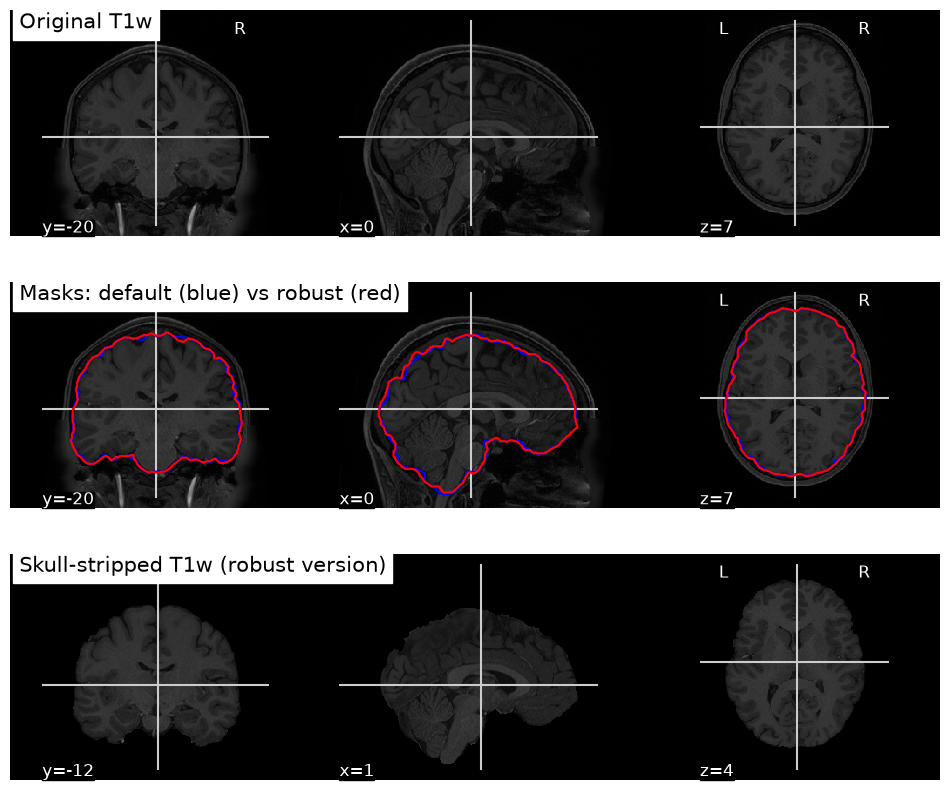


(ipykernel_launcher.py:987): Gtk-WARNING **: 14:27:50.612: Negative content width -11 (allocation 9, extents 10x10) while allocating gadget (node button, owner GtkButton)


In [32]:
# After inspection we choose the robust version
bet_path, resulting_mask_path = brain_robust, mask_robust

FIG_DIR = op.join(PROJECT_DIR, 'figures')
mkdir_no_exist(FIG_DIR)

fig, axes = plt.subplots(3, 1, figsize=(12, 10))
plotting.plot_anat(T1_PATH, title='Original T1w', axes=axes[0])
d = plotting.plot_anat(T1_PATH, title='Masks: default (blue) vs robust (red)', axes=axes[1])
d.add_contours(resulting_mask, levels=[0.5], colors='b')
d.add_contours(mask_robust, levels=[0.5], colors='r')
plotting.plot_anat(bet_path, title='Skull-stripped T1w (robust version)', axes=axes[2])

fig.savefig(op.join(FIG_DIR, '1a_skullstrip.png'), dpi=200, bbox_inches='tight')
plt.show()

### 1b. Tissue segmentation with `FAST`



In [6]:
anatomical_path = T1_PATH
bet_path = op.join(PREPROCESS_DATA_ROOT, 'T1w_stripped_robust.nii.gz')   


In [9]:
   fast_target = bet_path
   segmentation_path = op.join(PREPROCESS_DATA_ROOT, 'T1w_fast')

   if not op.exists(segmentation_path + '_seg.nii.gz'):
       fast(imgs=[fast_target], out=segmentation_path, n_classes=3)
   else:
       print("FAST outputs found")

FAST outputs found


In [10]:


fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(bet_path)
fsleyesDisplay.load(glob.glob(op.join(PREPROCESS_DATA_ROOT, '*pve_0*'))[0])
fsleyesDisplay.load(glob.glob(op.join(PREPROCESS_DATA_ROOT, '*pve_1*'))[0])
fsleyesDisplay.load(glob.glob(op.join(PREPROCESS_DATA_ROOT, '*pve_2*'))[0])
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'Red'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[2]).cmap = 'Green'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[3]).cmap = 'Blue'




(ipykernel_launcher.py:1093): Gtk-WARNING **: 21:28:22.747: Negative content width -11 (allocation 9, extents 10x10) while allocating gadget (node button, owner GtkButton)


#### Report figure: segmented tissues on the brain

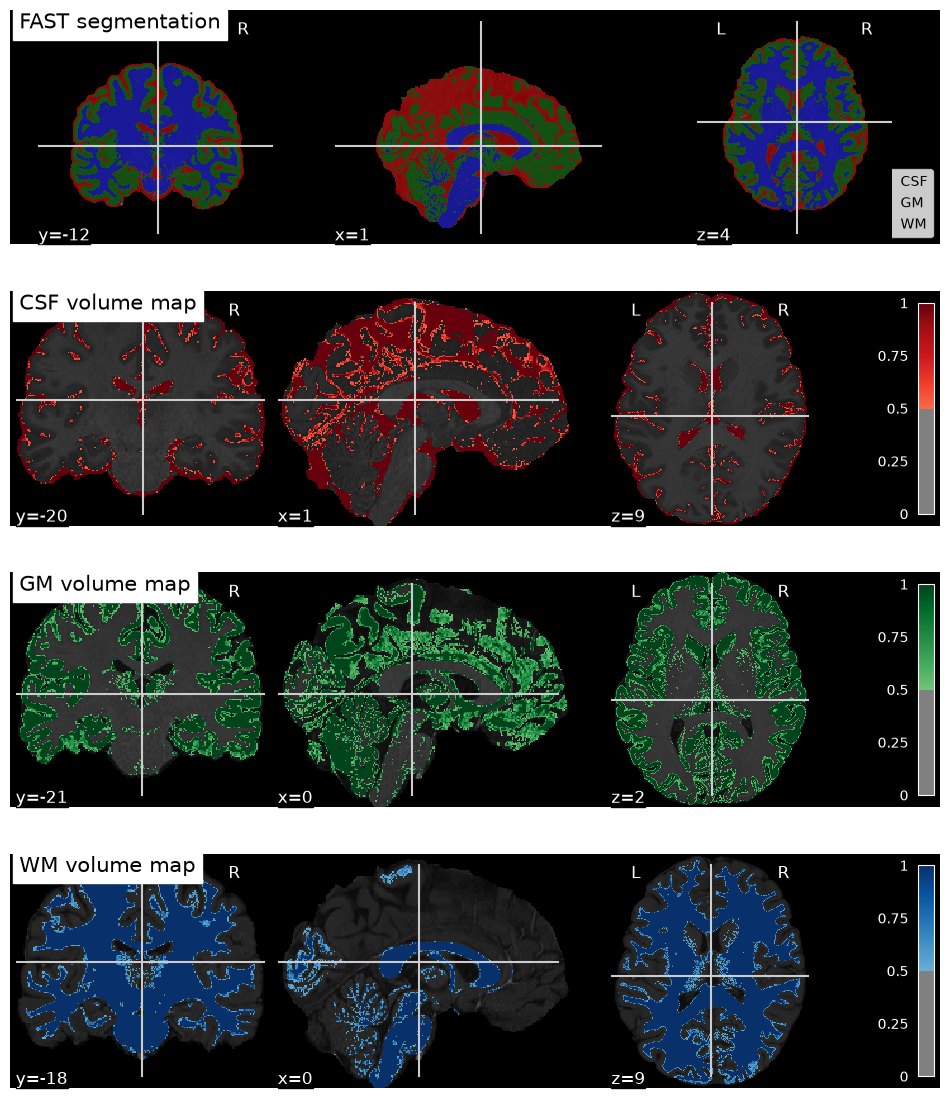

In [41]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

seg_file = segmentation_path + '_seg.nii.gz'   # hard labels: 1 = CSF, 2 = GM, 3 = WM
TISSUES = {
    'CSF': (op.join(PREPROCESS_DATA_ROOT, 'T1w_fast_pve_0.nii.gz'), 1, 'red',   'Reds'),
    'GM':  (op.join(PREPROCESS_DATA_ROOT, 'T1w_fast_pve_1.nii.gz'), 2, 'green', 'Greens'),
    'WM':  (op.join(PREPROCESS_DATA_ROOT, 'T1w_fast_pve_2.nii.gz'), 3, 'blue',  'Blues'),
}

fig, axes = plt.subplots(4, 1, figsize=(12, 14))

# Panel 1: hard segmentation, one fixed color per tissue
d = plotting.plot_anat(bet_path, title='FAST segmentation', axes=axes[0])
for name, (_, label, color, _) in TISSUES.items():
    tissue_mask = image.math_img(f'(img == {label}).astype(float)', img=seg_file)
    d.add_overlay(tissue_mask, cmap=ListedColormap([color]), threshold=0.5, alpha=0.5)

axes[0].legend(handles=[Patch(color=c, label=n) for n, (_, _, c, _) in TISSUES.items()],
               loc='lower right', fontsize=10, framealpha=0.8)

# Panels 2-4: partial volume maps, colored like their tissue
for ax, (name, (pve_path, _, _, cmap)) in zip(axes[1:], TISSUES.items()):
    plotting.plot_stat_map(pve_path, bg_img=bet_path, title=f'{name} volume map',
                           threshold=0.5, vmax=1, cmap=cmap, colorbar=True, axes=ax)

fig.savefig(op.join(FIG_DIR, '1b_segmentation.png'), dpi=200, bbox_inches='tight')
plt.show()

### 1c. Registration to MNI space with `FLIRT`



In [11]:

MNI_BRAIN = op.join(os.environ['FSLDIR'], 'data', 'standard', 'MNI152_T1_2mm_brain.nii.gz')
MNI_MASK  = op.join(os.environ['FSLDIR'], 'data', 'standard', 'MNI152_T1_2mm_brain_mask.nii.gz')


T1_BRAIN_MNI = op.join(PREPROCESS_DATA_ROOT, 'T1w_stripped_MNI.nii.gz')
T1_TO_MNI    = op.join(PREPROCESS_DATA_ROOT, 'T1w_to_MNI.mat')   # the affine transformation



#### Linear registration (12 degrees of freedom)


In [16]:
flirt(bet_path, MNI_BRAIN, out=T1_BRAIN_MNI, omat=T1_TO_MNI, dof=12, cost='normcorr')
print("Done with FLIRT.")

# The 4x4 affine matrix: top-left 3x3 = rotation/scaling/shearing, last column = translation
print(np.loadtxt(T1_TO_MNI))

Done with FLIRT.
[[ 1.07398295e+00 -1.25583158e-02 -2.81435437e-03 -5.24205625e+00]
 [ 2.23776502e-02  1.11827180e+00 -1.82341757e-04 -1.61609243e+01]
 [-1.01140336e-02 -1.28942076e-02  1.17795842e+00 -8.55549112e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


#### Bringing the segmentation to MNI space


In [15]:
segmentation_path = op.join(PREPROCESS_DATA_ROOT, 'T1w_fast')

In [14]:
SEG_MNI = op.join(PREPROCESS_DATA_ROOT, 'T1w_fast_seg_MNI.nii.gz')
flirt(segmentation_path + '_seg.nii.gz', MNI_BRAIN, out=SEG_MNI,
      applyxfm=True, init=T1_TO_MNI, interp='nearestneighbour')

for i, name in enumerate(['CSF', 'GM', 'WM']):
    flirt(segmentation_path + f'_pve_{i}.nii.gz', MNI_BRAIN,
          out=op.join(PREPROCESS_DATA_ROOT, f'T1w_fast_pve_{i}_MNI.nii.gz'),
          applyxfm=True, init=T1_TO_MNI, interp='trilinear')

print("Segmentation moved to MNI space.")

Segmentation moved to MNI space.


In [18]:
# Interactive check: registered T1 over the MNI template

fsleyesDisplay.load(MNI_BRAIN)
fsleyesDisplay.load(T1_BRAIN_MNI)

#### Report figure: T1 alignment with MNI before and after registration


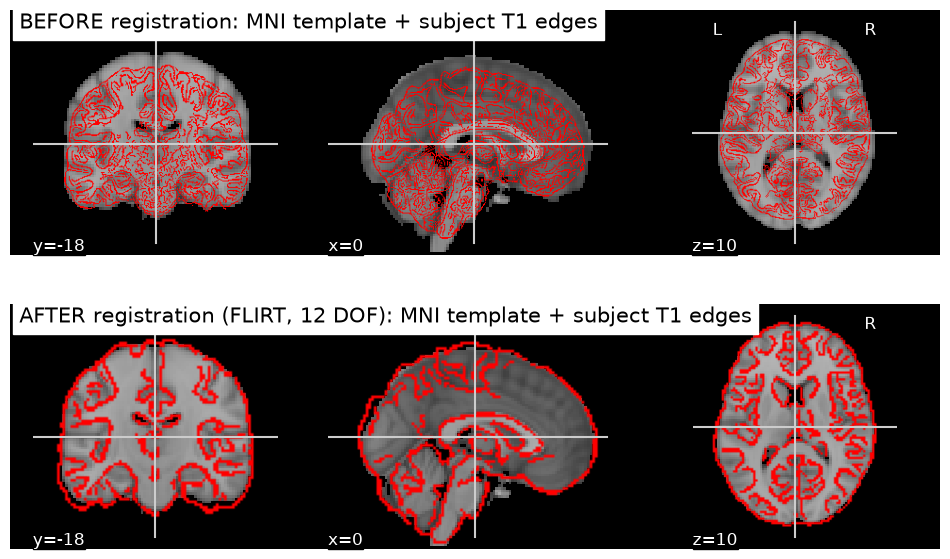

In [20]:
FIG_DIR = op.join(PROJECT_DIR, 'figures')
cuts = (0, -18, 10)
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

d0 = plotting.plot_anat(MNI_BRAIN, title='BEFORE registration: MNI template + subject T1 edges',
                        cut_coords=cuts, axes=axes[0])
d0.add_edges(bet_path, color='r')

d1 = plotting.plot_anat(MNI_BRAIN, title='AFTER registration (FLIRT, 12 DOF): MNI template + subject T1 edges',
                        cut_coords=cuts, axes=axes[1])
d1.add_edges(T1_BRAIN_MNI, color='r')

fig.savefig(op.join(FIG_DIR, '1c_registration_before_after.png'), dpi=200, bbox_inches='tight')
plt.show()